# Clustering Track — Obesity Levels Dataset
### 23CSE301 Machine Learning Capstone — Review 2

**Dataset:** `ObesityDataSet_raw_and_data_sinthetic.csv` (eating habits and physical condition of individuals; 2,111 rows, 17 columns)
**Goal:** Discover natural groupings of individuals from lifestyle and body measurements **without using labels during fitting**. The ground-truth column `NObeyesdad` is held aside and used *only* afterwards to interpret/validate the clusters.

This notebook covers:
- **Section A** — Dataset & EDA
- **Section B** — Preprocessing (clustering-appropriate: no train/test split, no label in the feature matrix)
- **Section C** — Clustering Track: K-Means and Agglomerative Hierarchical Clustering
  - Evaluation: Silhouette Score, Davies-Bouldin Index, Calinski-Harabasz Index
  - Elbow curve (K-Means), Dendrogram + linkage comparison (Hierarchical)
  - Visualisation: PCA 2-D for every algorithm, t-SNE for both algorithms
- **Section D** — Post-hoc validation against `NObeyesdad`, cluster profiling, conclusion

## Section A — Dataset & EDA

In [2]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score)
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet
from scipy.spatial.distance import pdist

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
palette = sns.color_palette('colorblind')

RANDOM_STATE = 42
DATA_PATH = 'ObesityDataSet_raw_and_data_sinthetic.csv'

df = pd.read_csv(DATA_PATH)
print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns")
df.head()

Shape: 2111 rows x 17 columns


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [3]:
print("Column dtypes:")
print(df.dtypes)

Column dtypes:
Gender                             object
Age                               float64
Height                            float64
Weight                            float64
family_history_with_overweight     object
FAVC                               object
FCVC                              float64
NCP                               float64
CAEC                               object
SMOKE                              object
CH2O                              float64
SCC                                object
FAF                               float64
TUE                               float64
CALC                               object
MTRANS                             object
NObeyesdad                         object
dtype: object


In [4]:
missing = df.isnull().sum()
print("Total missing values:", missing.sum())
print("Duplicate rows:", df.duplicated().sum())
df['NObeyesdad'].value_counts().to_frame('count').assign(percent=lambda d: (d['count']/len(df)*100).round(2))

Total missing values: 0
Duplicate rows: 24


,count,percent
NObeyesdad,,
Obesity_Type_I,351,16.63
Obesity_Type_III,324,15.35
Obesity_Type_II,297,14.07
Overweight_Level_I,290,13.74
Overweight_Level_II,290,13.74
Normal_Weight,287,13.60
Insufficient_Weight,272,12.88


**Observation (A1):** The dataset has 2,111 rows and 17 columns (8 numeric, 8 categorical features plus the `NObeyesdad` label) with **no missing values**. There are **24 exact duplicate rows**, which are removed in Section B. The seven obesity classes are almost perfectly balanced (12.9%-16.6% each), which is a hint that much of the data is synthetic (SMOTE-generated, as the file name says): about 65% of `Age` values and 39% of `FCVC` values are non-integers even though they are naturally whole numbers. This matters for clustering because synthetic points are interpolations between real ones, so they can blur the boundaries between groups.

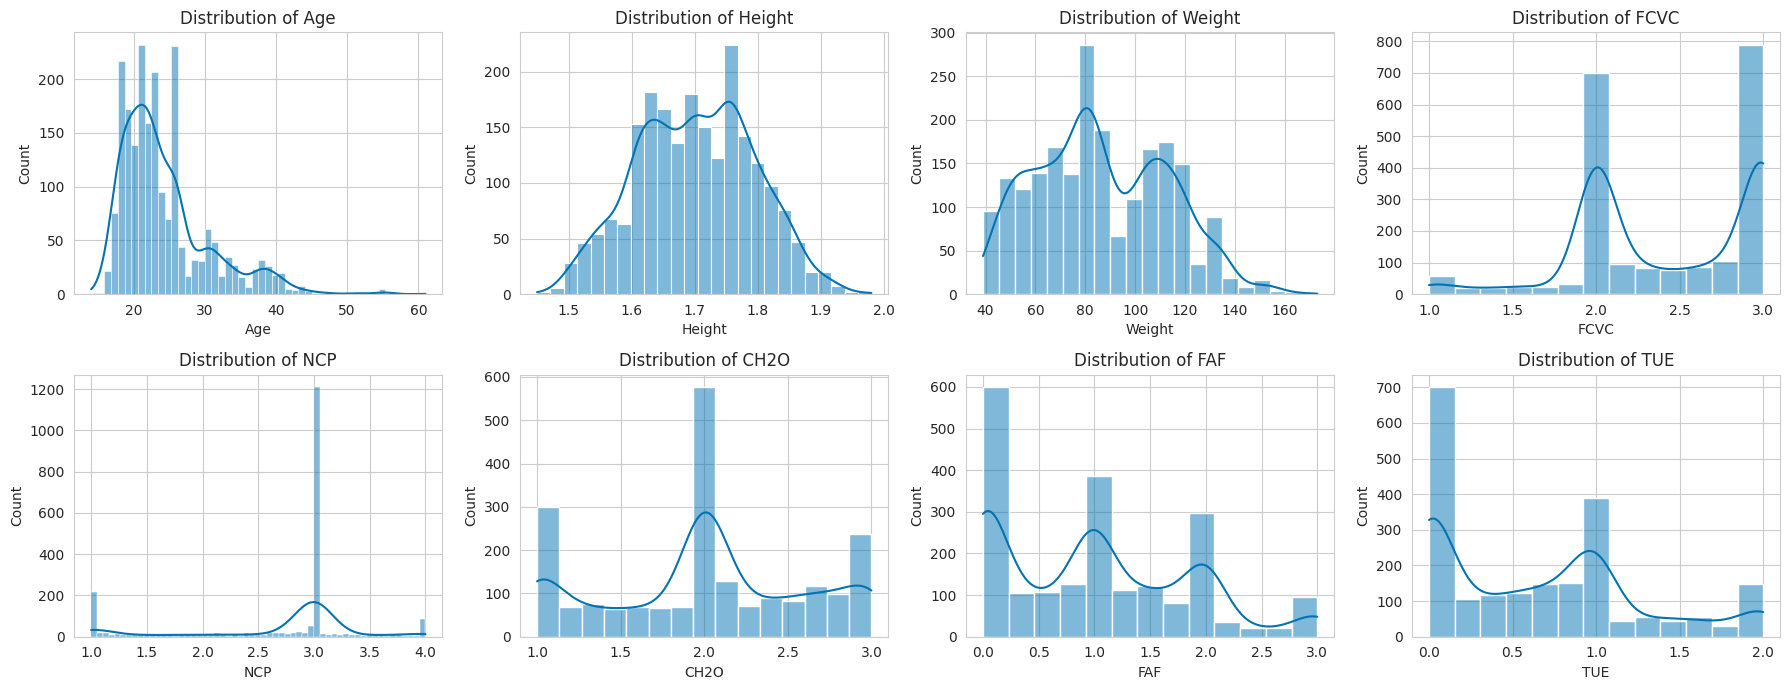

In [5]:
numeric_cols = ['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.flatten(), numeric_cols):
    sns.histplot(df[col], kde=True, ax=ax, color=palette[0])
    ax.set_title(f'Distribution of {col}')
plt.tight_layout(); plt.show()

**Observation:** `Age` is strongly right-skewed (skewness ≈ 1.5): most people are in their early-to-mid 20s with a thin tail up to 61. `NCP` (number of main meals) is left-skewed (≈ -1.1) with most people reporting 3 meals, and `TUE` and `FAF` are right-skewed. `Height` is almost symmetric and `Weight` is broad (about 40-173 kg). Because the features sit on very different scales (kg vs. 0-3 survey scores), they must be standardised before any distance-based clustering.

#### Categorical feature distributions

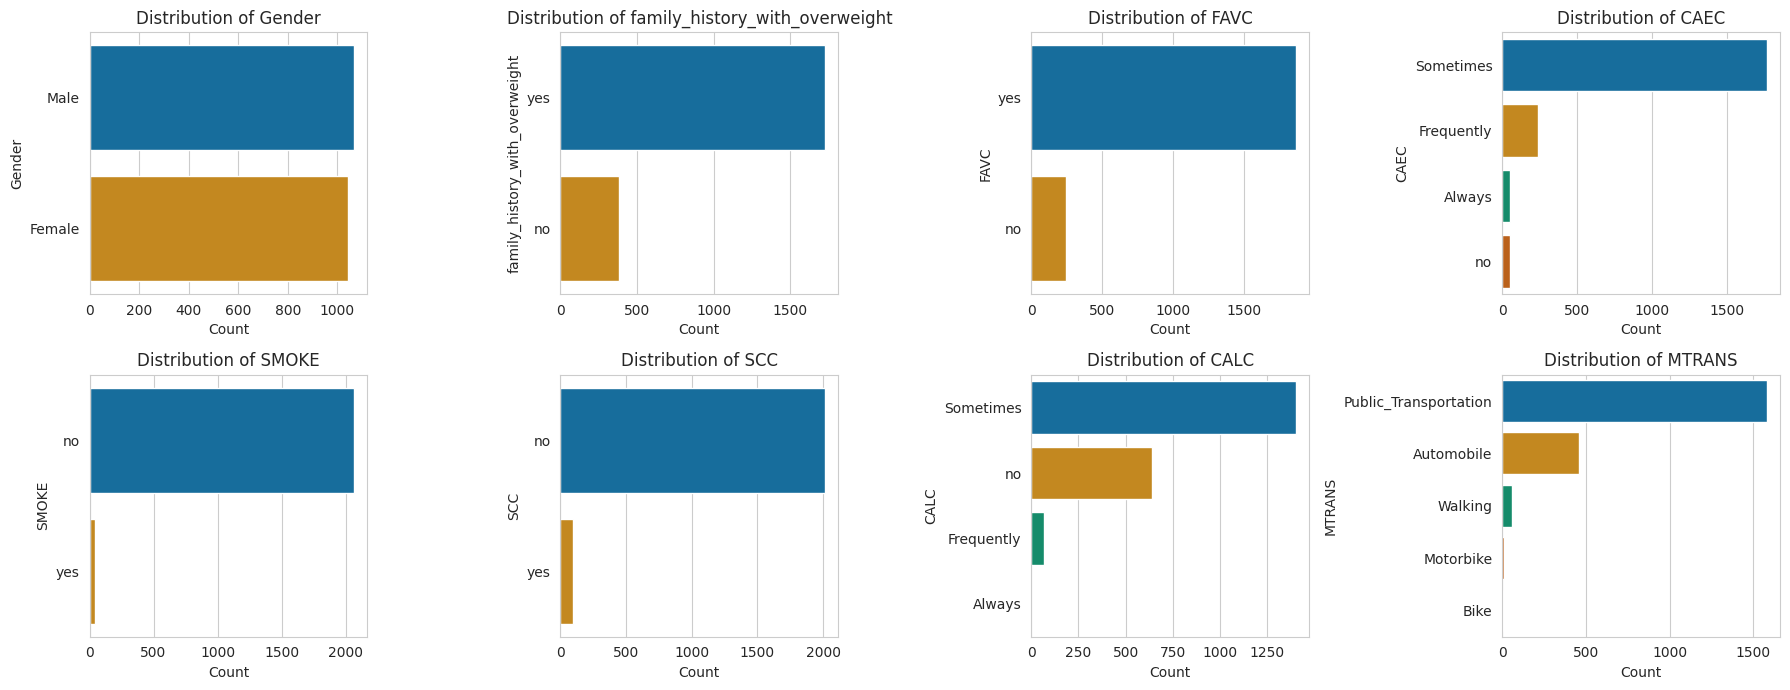

In [6]:
categorical_cols = ['Gender', 'family_history_with_overweight', 'FAVC', 'CAEC', 'SMOKE', 'SCC', 'CALC', 'MTRANS']
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.flatten(), categorical_cols):
    order = df[col].value_counts().index
    sns.countplot(y=col, data=df, order=order, palette=palette, ax=ax)
    ax.set_title(f'Distribution of {col}'); ax.set_xlabel('Count')
plt.tight_layout(); plt.show()

**Observation:** Gender is split almost evenly (50.6% male). Several categoricals are dominated by one level: 88% report high-calorie food (`FAVC` = yes), 82% have a family history of overweight, 98% do not smoke, 95% do not monitor calories (`SCC` = no), 84% eat between meals only 'Sometimes', and 75% use public transport. Near-constant features such as `SMOKE` carry little structure, so they will contribute almost nothing to cluster separation, while `CALC`, `CAEC` and `MTRANS` have more even splits.

#### Correlation heatmap (numeric features)

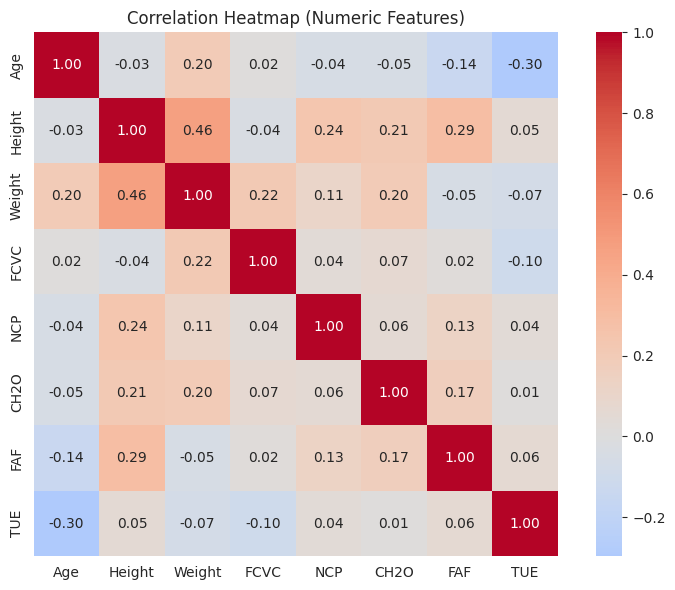

In [7]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True, ax=ax)
ax.set_title('Correlation Heatmap (Numeric Features)')
plt.tight_layout(); plt.show()

**Observation:** Correlations among numeric features are weak to moderate, with the strongest being `Height`-`Weight` (0.46), `Age`-`TUE` (-0.30) and `Height`-`FAF` (0.29). There is no heavy multicollinearity, so no numeric feature is redundant. The absence of strong correlations also means PCA will not collapse the data into one or two dominant directions, which anticipates the low explained variance seen in Section C.

## Section B — Preprocessing
Clustering-specific choices:
- **Duplicates removed** (they would artificially inflate density in some clusters).
- **Labels separated:** `NObeyesdad` is moved into `y_true` and **never** enters the feature matrix; it is used only in Section D.
- **Scaling is mandatory:** K-Means and Ward/Euclidean linkage are distance-based, so `Weight` (~40-170) would swamp `FAF` (0-3) without `StandardScaler`.
- **Encoding:** binary categoricals → single 0/1 column; multi-level categoricals (`CAEC`, `CALC`, `MTRANS`) → one-hot.
- **No train/test split:** clustering is unsupervised, so all rows are clustered; the split is only needed for supervised generalisation.
- The transformer is wrapped in a `ColumnTransformer` so the same steps are reproducible.

In [8]:
df = df.drop_duplicates().reset_index(drop=True)
print("Rows after dropping duplicates:", len(df))

# Hold the ground-truth labels aside - used ONLY for post-hoc interpretation
y_true = df['NObeyesdad'].copy()
X_raw = df.drop(columns=['NObeyesdad'])

numeric_features = ['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']
categorical_features = ['Gender', 'family_history_with_overweight', 'FAVC', 'CAEC',
                        'SMOKE', 'SCC', 'CALC', 'MTRANS']

preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), numeric_features),
    ('cat', OneHotEncoder(drop='if_binary', sparse_output=False), categorical_features)
])

X = preprocessor.fit_transform(X_raw)
feature_names = preprocessor.get_feature_names_out()
print("Feature matrix shape:", X.shape)
print(list(feature_names))

Rows after dropping duplicates: 2087
Feature matrix shape: (2087, 26)
['num__Age', 'num__Height', 'num__Weight', 'num__FCVC', 'num__NCP', 'num__CH2O', 'num__FAF', 'num__TUE', 'cat__Gender_Male', 'cat__family_history_with_overweight_yes', 'cat__FAVC_yes', 'cat__CAEC_Always', 'cat__CAEC_Frequently', 'cat__CAEC_Sometimes', 'cat__CAEC_no', 'cat__SMOKE_yes', 'cat__SCC_yes', 'cat__CALC_Always', 'cat__CALC_Frequently', 'cat__CALC_Sometimes', 'cat__CALC_no', 'cat__MTRANS_Automobile', 'cat__MTRANS_Bike', 'cat__MTRANS_Motorbike', 'cat__MTRANS_Public_Transportation', 'cat__MTRANS_Walking']


**Observation (B):** After removing duplicates 2,087 rows remain. Standardising the 8 numeric columns and encoding the 8 categoricals gives a **26-feature** matrix (binary columns collapsed to one, multi-level columns one-hot encoded). Keeping `NObeyesdad` out of `X` ensures the clustering is genuinely unsupervised. Note that `Height` and `Weight` are kept as features, so the clusters will naturally be heavily driven by body size; this is a deliberate choice and is discussed again in Section D.

## Section C — Clustering Track
### Shared helper functions
Reusable functions keep the notebook modular: one computes the three mandatory internal metrics, one draws the PCA scatter, one draws the t-SNE scatter.

In [9]:
def evaluate_clustering(X, labels):
    """Return the three mandatory internal validity metrics for a set of cluster labels."""
    return {
        'Silhouette (higher better)': silhouette_score(X, labels),
        'Davies-Bouldin (lower better)': davies_bouldin_score(X, labels),
        'Calinski-Harabasz (higher better)': calinski_harabasz_score(X, labels),
    }

def plot_embedding(emb, labels, title, ax, xlabel='Dim 1', ylabel='Dim 2'):
    """2-D scatter of an embedding (PCA / t-SNE) colour-coded by cluster label."""
    for i, c in enumerate(np.unique(labels)):
        m = labels == c
        ax.scatter(emb[m, 0], emb[m, 1], s=14, alpha=0.7, color=sns.color_palette('tab10')[i % 10],
                   label=f'Cluster {c} (n={m.sum()})')
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    ax.legend(fontsize=7, markerscale=1.5)

# 2-component PCA of the preprocessed data (mandatory visualisation space)
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X)
print("PCA explained variance ratio:", pca.explained_variance_ratio_.round(3),
      "| total:", pca.explained_variance_ratio_.sum().round(3))

PCA explained variance ratio: [0.196 0.163] | total: 0.359


### C1 — Algorithm 1: K-Means Clustering
#### Choosing *k*: Elbow curve (inertia vs. k) with Silhouette as a cross-check

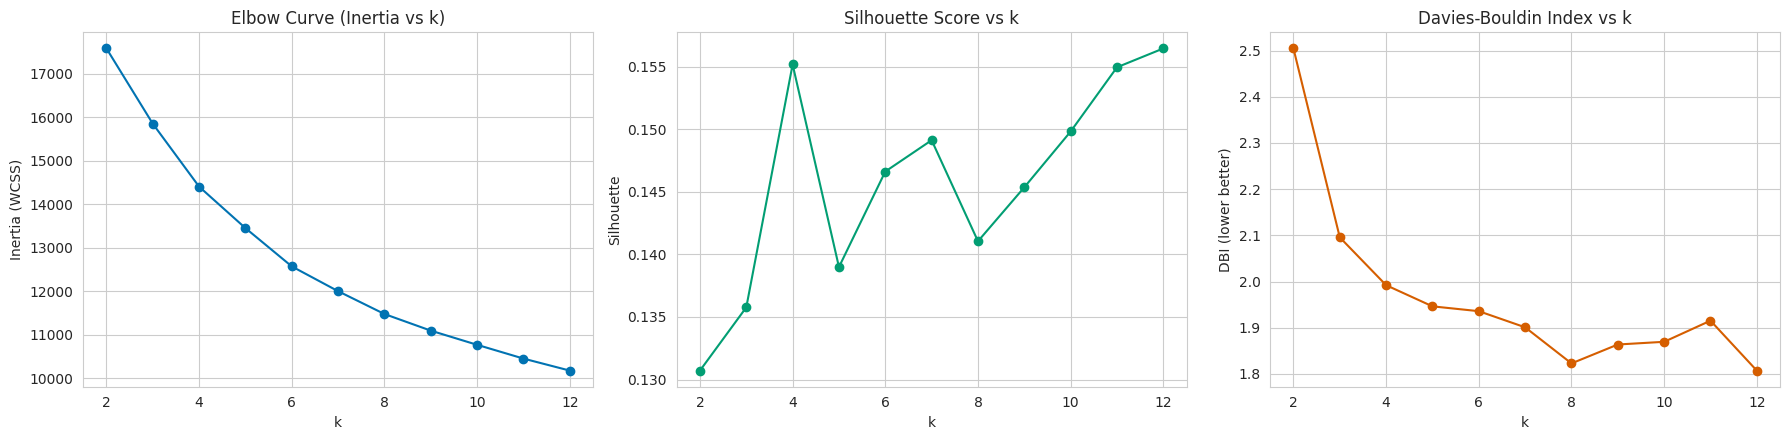

,Inertia,Silhouette,Davies-Bouldin,Calinski-Harabasz
k,,,,
2,17587.0116,0.1307,2.5047,314.7231
3,15855.7749,0.1358,2.0957,288.2320
4,14408.1636,0.1552,1.9922,281.1200
5,13454.8510,0.1390,1.9464,262.5491
6,12574.3293,0.1466,1.9359,253.7839
7,12004.2844,0.1491,1.9010,237.8850
8,11479.2521,0.1410,1.8228,226.7089
9,11097.1788,0.1454,1.8637,214.0446
10,10771.2007,0.1498,1.8696,202.9098


In [10]:
k_range = range(2, 13)
inertias, sil_scores, db_scores, ch_scores = [], [], [], []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X, km.labels_))
    db_scores.append(davies_bouldin_score(X, km.labels_))
    ch_scores.append(calinski_harabasz_score(X, km.labels_))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].plot(list(k_range), inertias, 'o-', color=palette[0])
axes[0].set_title('Elbow Curve (Inertia vs k)'); axes[0].set_xlabel('k'); axes[0].set_ylabel('Inertia (WCSS)')
axes[1].plot(list(k_range), sil_scores, 'o-', color=palette[2])
axes[1].set_title('Silhouette Score vs k'); axes[1].set_xlabel('k'); axes[1].set_ylabel('Silhouette')
axes[2].plot(list(k_range), db_scores, 'o-', color=palette[3])
axes[2].set_title('Davies-Bouldin Index vs k'); axes[2].set_xlabel('k'); axes[2].set_ylabel('DBI (lower better)')
plt.tight_layout(); plt.show()

pd.DataFrame({'k': list(k_range), 'Inertia': inertias, 'Silhouette': sil_scores,
              'Davies-Bouldin': db_scores, 'Calinski-Harabasz': ch_scores}).round(4).set_index('k')

In [11]:
# Quantify the elbow: largest 'bend' = largest second difference of inertia
d2 = np.diff(inertias, 2)
elbow_k = list(k_range)[int(np.argmax(d2)) + 1]
sil_k = list(k_range)[int(np.argmax(sil_scores))]
print("Elbow (max 2nd difference of inertia) suggests k =", elbow_k)
print("Best silhouette suggests              k =", sil_k)

Elbow (max 2nd difference of inertia) suggests k = 4
Best silhouette suggests              k = 12


**Observation (choice of k):** The elbow curve has no sharp elbow: inertia falls smoothly from k=2 to k=12, which already signals weak cluster structure. The largest bend of the curve (maximum second difference of inertia) is at **k = 4**, and k=4 is also the local peak of the silhouette curve for small k (0.155 vs. 0.131 at k=2, 0.136 at k=3 and 0.139 at k=5). Silhouette keeps rising slowly again for k ≥ 10 (max at k=12), but those values are only marginally higher and a 10-12 cluster solution would be hard to interpret, so the parsimonious **k = 4** is used for both algorithms. (The data has 7 labelled obesity classes, but they are not expected to appear as 7 separate geometric clusters; see Section D.)

In [12]:
K_FINAL = 4
kmeans = KMeans(n_clusters=K_FINAL, n_init=10, random_state=RANDOM_STATE).fit(X)
km_labels = kmeans.labels_
print(f"K-Means fitted with k={K_FINAL}. Cluster sizes:")
print(pd.Series(km_labels).value_counts().sort_index().to_string())

K-Means fitted with k=4. Cluster sizes:
0    302
1    742
2    703
3    340


### C2 — Algorithm 2: Agglomerative Hierarchical Clustering
#### Dendrogram (Ward linkage)

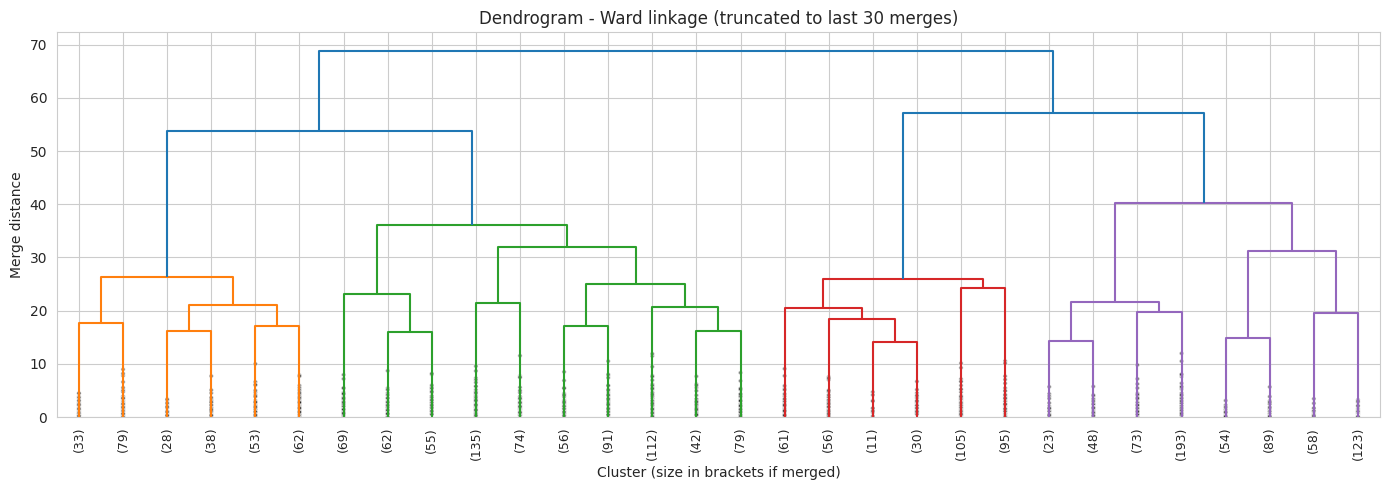

In [13]:
Z_ward = linkage(X, method='ward')

fig, ax = plt.subplots(figsize=(14, 5))
dendrogram(Z_ward, truncate_mode='lastp', p=30, leaf_rotation=90, leaf_font_size=9,
           show_contracted=True, ax=ax)
ax.set_title('Dendrogram - Ward linkage (truncated to last 30 merges)')
ax.set_xlabel('Cluster (size in brackets if merged)'); ax.set_ylabel('Merge distance')
plt.tight_layout(); plt.show()

**Observation (dendrogram):** The Ward merge heights for the last merges are roughly 68.9 (2→1), 57.1 (3→2), 53.8 (4→3) and then 40.3 (5→4), so the **largest gap between consecutive merge heights (≈13.5) lies between the 5→4 and 4→3 merges**. Cutting the tree in that gap gives **4 clusters**, which agrees with the elbow/silhouette choice for K-Means and makes the two algorithms directly comparable.

#### Linkage strategy comparison (ward / complete / average / single)

In [14]:
linkages = ['ward', 'complete', 'average', 'single']
dist = pdist(X)                    # condensed Euclidean distances for cophenetic correlation
link_rows = []
for method in linkages:
    for k in [K_FINAL]:
        agg = AgglomerativeClustering(n_clusters=k, linkage=method).fit(X)
        coph, _ = cophenet(linkage(X, method=method), dist)
        row = {'Linkage': method, 'k': k, 'Cophenetic corr.': coph}
        row.update(evaluate_clustering(X, agg.labels_))
        row['Smallest cluster size'] = np.bincount(agg.labels_).min()
        link_rows.append(row)
link_df = pd.DataFrame(link_rows).set_index('Linkage').round(4)
link_df

,k,Cophenetic corr.,Silhouette (higher better),Davies-Bouldin (lower better),Calinski-Harabasz (higher better),Smallest cluster size
Linkage,,,,,,
ward,4,0.4239,0.1389,2.0647,255.7538,293
complete,4,0.4612,0.0794,2.3850,128.0449,9
average,4,0.6122,0.1470,0.8265,4.6617,1
single,4,0.5020,0.3169,0.5041,3.9759,1


**Observation (linkage comparison):** Single and average linkage show deceptively good Davies-Bouldin and silhouette values (single: silhouette 0.317, DBI 0.50) but this is an artefact: their smallest cluster has just **1 point**, i.e. they split off a few outliers and put almost everything else in one giant cluster (their Calinski-Harabasz scores are also tiny, 4.0 and 4.7). This is the classic *chaining* behaviour of single/average linkage on noisy, overlapping data. Complete linkage also produces a tiny cluster (9 points) and the worst silhouette (0.079). **Ward linkage** is the only strategy that produces four reasonably sized clusters (smallest = 293) with a strong Calinski-Harabasz score (255.8), so it is selected. Ward's merge criterion (minimising within-cluster variance) is also the hierarchical counterpart of K-Means' objective.

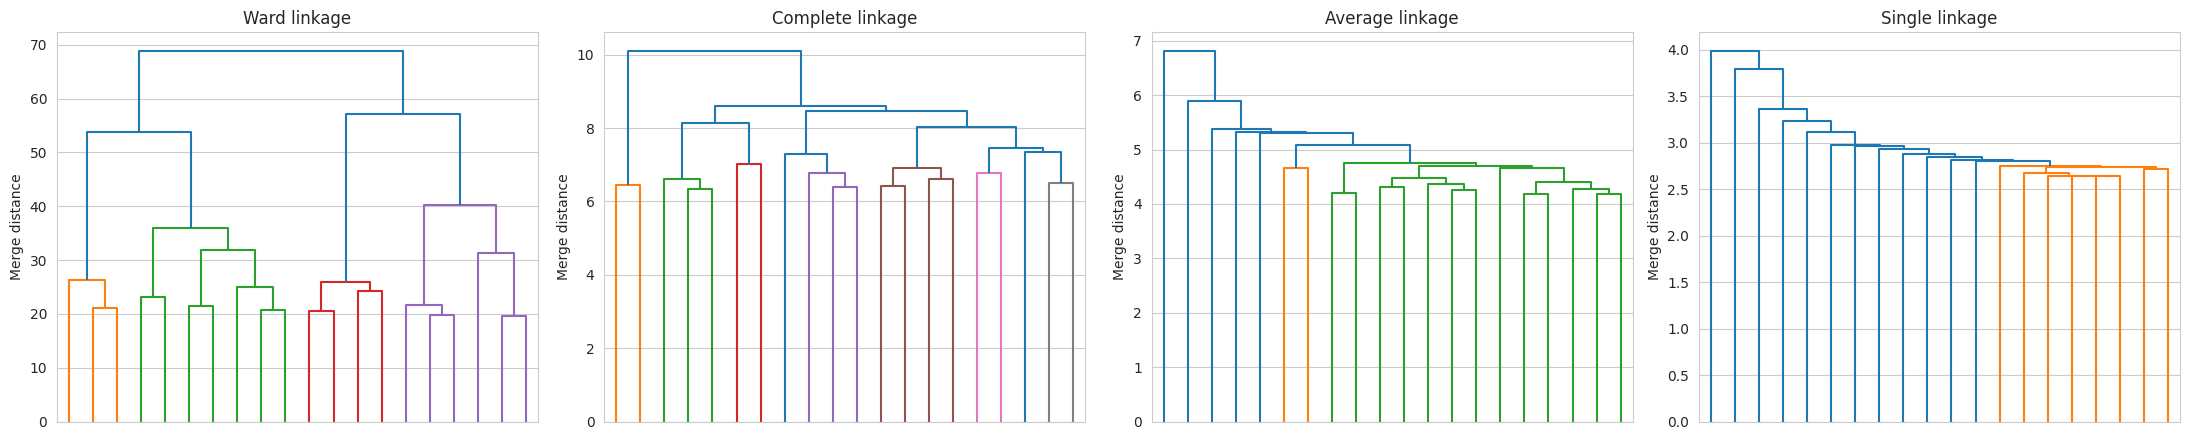

In [15]:
# Dendrograms for each linkage side by side
fig, axes = plt.subplots(1, 4, figsize=(22, 4.5))
for ax, method in zip(axes, linkages):
    dendrogram(linkage(X, method=method), truncate_mode='lastp', p=20, no_labels=True, ax=ax)
    ax.set_title(f'{method.capitalize()} linkage'); ax.set_ylabel('Merge distance')
plt.tight_layout(); plt.show()

In [16]:
BEST_LINKAGE = 'ward'
agglo = AgglomerativeClustering(n_clusters=K_FINAL, linkage=BEST_LINKAGE).fit(X)
agg_labels = agglo.labels_
print(f"Agglomerative clustering fitted (linkage='{BEST_LINKAGE}', k={K_FINAL}). Cluster sizes:")
print(pd.Series(agg_labels).value_counts().sort_index().to_string())

Agglomerative clustering fitted (linkage='ward', k=4). Cluster sizes:
0    661
1    775
2    358
3    293


### C3 — Evaluation metrics (all algorithms)
Silhouette Score, Davies-Bouldin Index, and Calinski-Harabasz Index for both algorithms in one table.

In [17]:
cluster_results = {
    f'K-Means (k={K_FINAL})': km_labels,
    f'Agglomerative ({BEST_LINKAGE}, k={K_FINAL})': agg_labels,
}
metrics_df = pd.DataFrame({name: evaluate_clustering(X, lab) for name, lab in cluster_results.items()}).T.round(4)
metrics_df

,Silhouette (higher better),Davies-Bouldin (lower better),Calinski-Harabasz (higher better)
K-Means (k=4),0.1552,1.9922,281.1200
"Agglomerative (ward, k=4)",0.1389,2.0647,255.7538


**Observation (metrics):** K-Means is slightly better on all three internal metrics: Silhouette 0.155 vs. 0.139, Davies-Bouldin 1.99 vs. 2.06 (lower is better) and Calinski-Harabasz 281.1 vs. 255.8. The differences are small, so the two methods find similar partitions. More importantly, **absolute silhouette values around 0.15 indicate weak, heavily overlapping clusters**: the lifestyle/body data forms a continuum rather than well-separated groups. This is expected with 26 mixed features, many noisy survey-type variables, and synthetic interpolated samples. K-Means is preferred on the internal metrics because it directly optimises compact, spherical clusters, which is what these metrics reward.

### C4 — Cluster visualisation
#### PCA (2 components) — every algorithm

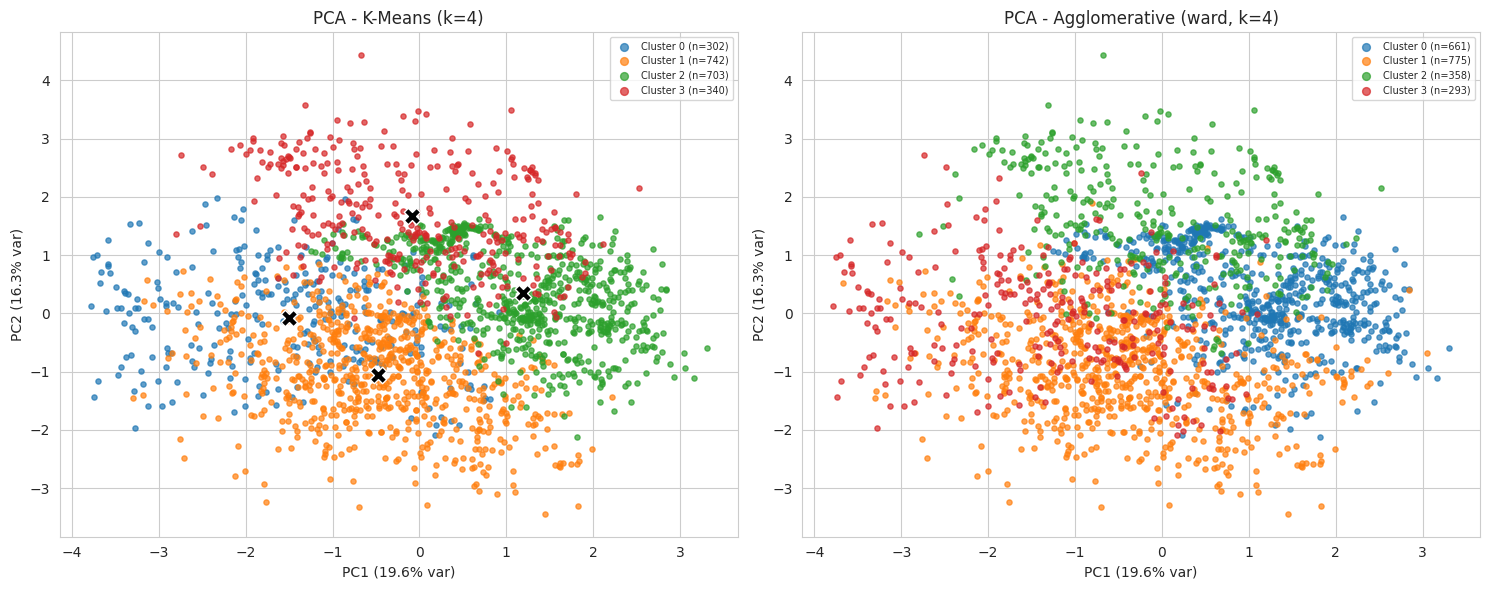

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
xl = f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% var)'
yl = f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% var)'
for ax, (name, lab) in zip(axes, cluster_results.items()):
    plot_embedding(X_pca, lab, f'PCA - {name}', ax, xl, yl)
# show K-Means centroids projected into PCA space
cent = pca.transform(kmeans.cluster_centers_)
axes[0].scatter(cent[:, 0], cent[:, 1], c='black', marker='X', s=140, edgecolor='white', label='Centroids')
plt.tight_layout(); plt.show()